# Harmonic inversion and Lorentzian lines

This notebook introduces `pyharminv` with synthetic data. We build a signal
from damped cosines with known parameters, recover them by harmonic
inversion and compare with the Fourier spectrum.

The model behind everything is

$$c(t) = \sum_k d_k\, e^{-i \omega_k t}, \qquad \omega_k = \Omega_k - \tfrac{i}{2}\Gamma_k ,$$

where $\Omega_k$ is a line centre, $\Gamma_k$ its full width at half maximum
and $d_k$ a complex amplitude.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from pyharminv import harminv, lorentzian, synthetic_signal

plt.rcParams["figure.figsize"] = (9, 4)

## 1. A signal from three damped cosines

Each term is $A\, e^{-\Gamma t/2} \cos(\Omega t - \varphi)$. For a real
signal `pyharminv` uses $x(t) = \mathrm{Re}\sum_k d_k e^{-i\omega_k t}$, so
$d_k = A_k e^{i \varphi_k}$.

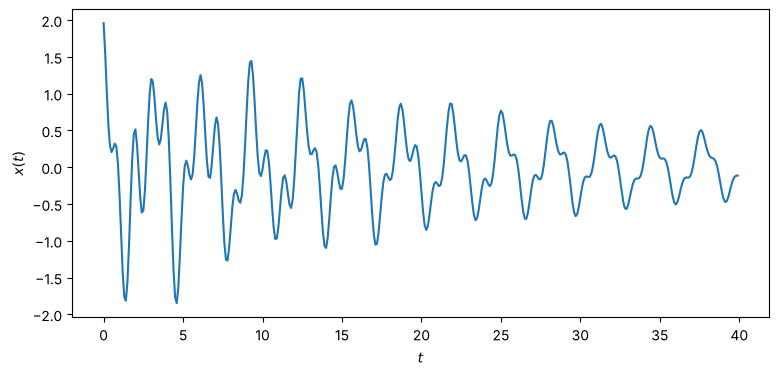

In [2]:
Omega = np.array([2.0, 3.5, 6.0])     # line centres
Gamma = np.array([0.05, 0.2, 0.1])     # full widths at half maximum
A     = np.array([1.0, 0.6, 0.8])      # amplitudes
phi   = np.array([0.0, 0.5, -1.0])     # phases

omega_true = Omega - 0.5j * Gamma
d_true = A * np.exp(1j * phi)

dt = 0.1
t = dt * np.arange(400)
x = synthetic_signal(t, omega_true, d_true, real=True)

plt.plot(t, x)
plt.xlabel("$t$"); plt.ylabel("$x(t)$");

## 2. Harmonic inversion

One call returns all modes. The printout shows the complex frequencies,
quality factors $Q = \Omega/\Gamma$, amplitudes, phases and an error
estimate for each mode.

In [3]:
result = harminv(x, dt)
result

HarmInvResult with 3 modes (real signal)
    omega.real     omega.imag          Q         |d|    arg d     error
             2         -0.025         40           1   0.0000   3.2e-14
           3.5           -0.1       17.5         0.6   0.5000     1e-14
             6          -0.05         60         0.8  -1.0000   1.9e-14

In [4]:
print("centres:", result.center)
print("widths: ", result.width)
print("phases: ", result.phase)
print("max. deviation of omega:", np.max(np.abs(result.omega - omega_true)))

centres: [2.  3.5 6. ]
widths:  [0.05 0.2  0.1 ]
phases:  [ 1.61830043e-13  5.00000000e-01 -1.00000000e+00]
max. deviation of omega: 1.5160363706167604e-14


The parameters come back to rounding accuracy. The fitted signal
reproduces the data:

max. residual: 1.8723911310303265e-13


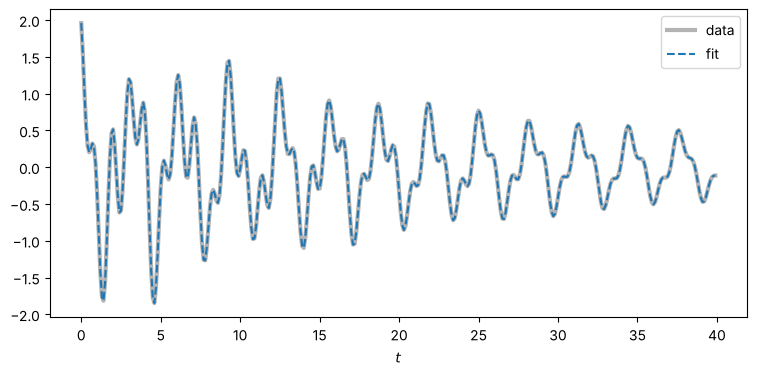

In [5]:
plt.plot(t, x, lw=3, color="0.7", label="data")
plt.plot(t, result.reconstruct(t), "--", label="fit")
plt.xlabel("$t$"); plt.legend();
print("max. residual:", np.max(np.abs(result.reconstruct(t) - x)))

## 3. Lorentzian lines in the spectrum

The one-sided Fourier transform $\int_0^\infty x(t) e^{i\omega t} dt$ of a
damped cosine has, near $\Omega$, a real part shaped like a Lorentzian of
width $\Gamma$ and height $A/\Gamma$. `lorentzians()` returns these
parameters, and `spectrum()` the full complex spectrum of the fit (with the
dispersive parts caused by the phases).

centre 2.0000   FWHM 0.0500   height 20.000
centre 3.5000   FWHM 0.2000   height 3.000
centre 6.0000   FWHM 0.1000   height 8.000


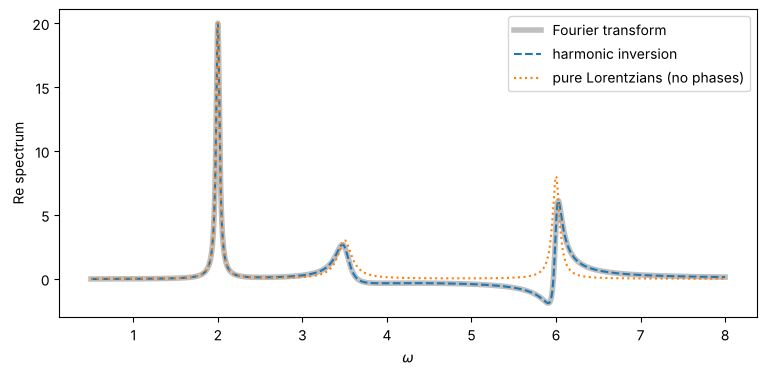

In [6]:
lines = result.lorentzians()
for c, g, h in zip(lines["center"], lines["fwhm"], lines["height"]):
    print(f"centre {c:.4f}   FWHM {g:.4f}   height {h:.3f}")

# Fourier transform of a long version of the signal, so that it has decayed
t_long = dt * np.arange(20000)
x_long = synthetic_signal(t_long, omega_true, d_true, real=True)
w = np.linspace(0.5, 8, 3000)
ft = (np.exp(1j * np.outer(w, t_long)) @ x_long) * dt - 0.5 * x_long[0] * dt

plt.plot(w, ft.real, lw=4, color="0.75", label="Fourier transform")
plt.plot(w, result.spectrum(w).real, "--", label="harmonic inversion")
plt.plot(w, lorentzian(w, lines["center"], lines["fwhm"], lines["height"]),
         ":", label="pure Lorentzians (no phases)")
plt.xlabel(r"$\omega$"); plt.ylabel("Re spectrum"); plt.legend();

The line at $\Omega = 6$ has phase $-1$, which mixes in a dispersive
shape; the pure Lorentzians show only the absorptive part.

## 4. Beyond the Fourier resolution

A signal of duration $T$ has the Fourier resolution $2\pi/T$. Harmonic
inversion is not bound to it. Here two overlapping lines lie a quarter of
the resolution apart, and the signal is short.

In [7]:
omega_pair = np.array([5.0 - 0.06j, 5.04 - 0.05j])
d_pair = np.array([1.0, 0.8])
t_short = dt * np.arange(400)
T = t_short[-1]
print("Fourier resolution 2 pi / T =", 2 * np.pi / T)
print("line spacing                =", omega_pair[1].real - omega_pair[0].real)

x_pair = synthetic_signal(t_short, omega_pair, d_pair, real=True)
pair = harminv(x_pair, dt).select(min_magnitude=1e-3)
pair

Fourier resolution 2 pi / T = 0.15747331596941316
line spacing                = 0.040000000000000036


HarmInvResult with 2 modes (real signal)
    omega.real     omega.imag          Q         |d|    arg d     error
             5          -0.06      41.67           1  -0.0000     2e-13
          5.04          -0.05       50.4         0.8   0.0000   1.5e-13

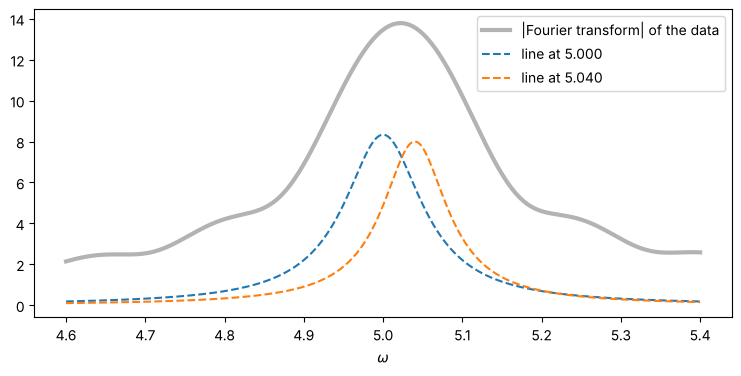

In [8]:
w = np.linspace(4.6, 5.4, 800)
fft_short = (np.exp(1j * np.outer(w, t_short)) @ x_pair) * dt
lines = pair.lorentzians()

plt.plot(w, np.abs(fft_short), lw=3, color="0.7", label="|Fourier transform| of the data")
for c, g, h in zip(lines["center"], lines["fwhm"], lines["height"]):
    plt.plot(w, lorentzian(w, c, g, h), "--", label=f"line at {c:.3f}")
plt.xlabel(r"$\omega$"); plt.legend();

The Fourier transform shows a single, broadened peak with
truncation ripples; harmonic inversion separates both lines with their
exact centres, widths and amplitudes.